# Analiza i wizualizacja meczu euro 2020 Szwecja - Polska

## Pozyskanie danych event po evencie

In [1]:
from get_data.get_data import get_merged_events

MATCH_ID = 3788776

EVENTS_TO_ANALIZE = ['passes', 'carrys', 'ball_receipts', 'ball_recoverys', 'dribbles', 'blocks', 'clearances', 
'dispossesseds', 'errors', 'foul_committeds', 'foul_wons', 'half_ends', 'injury_stoppages', 'interceptions', 'miscontrols', 'shots']

merged_events = get_merged_events(EVENTS_TO_ANALIZE, MATCH_ID)

merged_events.head(5)

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,duration,related_events,event,match_id,possession_team_id,player_id,under_pressure,off_camera,counterpress,out
0,9e9ec22a-f1cf-4460-ba53-c786f7b05287,5,1,00:00:00.080,0,0,Pass,2,Sweden,From Kick Off,...,1.422263,[b3c8e55c-581c-4c68-b722-446903bbd574],"{'recipient': {'id': 3702, 'name': 'Victor Nil...",3788776,790,5617.0,,,,
1,b3c8e55c-581c-4c68-b722-446903bbd574,6,1,00:00:01.502,0,1,Ball Receipt*,2,Sweden,From Kick Off,...,,[9e9ec22a-f1cf-4460-ba53-c786f7b05287],,3788776,790,3702.0,,,,
2,f0280b81-7d48-4071-bd0e-c479ccda4a03,7,1,00:00:01.502,0,1,Carry,2,Sweden,From Kick Off,...,1.150845,"[470d2435-f5a4-46f9-aa0c-af2ce5e92f31, b3c8e55...","{'end_location': [36.8, 41.1]}",3788776,790,3702.0,,,,
3,470d2435-f5a4-46f9-aa0c-af2ce5e92f31,8,1,00:00:02.653,0,2,Pass,2,Sweden,From Kick Off,...,3.210068,[e7e53c4b-6ee1-4f04-9a41-c4d3906d072e],"{'recipient': {'id': 5612, 'name': 'Mikael Lus...",3788776,790,3702.0,,,,
4,e7e53c4b-6ee1-4f04-9a41-c4d3906d072e,9,1,00:00:05.863,0,5,Ball Receipt*,2,Sweden,From Kick Off,...,,[470d2435-f5a4-46f9-aa0c-af2ce5e92f31],,3788776,790,5612.0,,,,


## Ujednolicenie perspektywy lewa-prawa bramka

In [2]:
from dataframe_modify.generalize_perspective import generalize_perspective

merged_events = generalize_perspective(merged_events)

['Pass' 'Ball Receipt*' 'Carry' ... 'Pass' 'Half End' 'Half End']


## Dodanie stref boiska

In [3]:
from dataframe_modify.grid_areas import add_areas_and_pos

merged_events = add_areas_and_pos(merged_events)

merged_events['area_code']

0       F5D5
1         D5
2       D5D4
3       D4E2
4         E2
        ... 
2470      B1
2471    B1B2
2472    B2Z6
2473        
2474        
Name: area_code, Length: 2475, dtype: object

## Podział na sekwencje

In [4]:
from sequences.get_sequences import get_sequences_by_possession

In [5]:
sequences = get_sequences_by_possession(merged_events)
sequences[2]

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,off_camera,counterpress,out,start_x,start_y,end_x,end_y,start_area,end_area,area_code
37,175aaf0a-2a80-4fca-848a-213e6f0d36d3,46,1,00:00:38.375,0,38,Pass,4,Sweden,Regular Play,...,,,,41.8,51.0,50.3,59.4,E3,F3,E3F3
38,4d2a73b8-89e3-4fc2-b7af-49285962e826,47,1,00:00:39.466,0,39,Ball Receipt*,4,Sweden,Regular Play,...,,,,50.3,59.4,,,F3,,F3
39,362af604-7d7e-456c-a3d9-5e6c34dcaceb,48,1,00:00:39.466,0,39,Pass,4,Sweden,Regular Play,...,,,,50.3,59.4,39.5,69.9,F3,D2,F3D2
40,c84fdfbd-27ea-42b7-a617-50c7de454aec,49,1,00:00:40.562,0,40,Ball Receipt*,4,Sweden,Regular Play,...,,,,39.5,69.9,,,D2,,D2
41,adf26028-a63e-49d2-af2e-da566cbf0b75,50,1,00:00:40.562,0,40,Carry,4,Sweden,Regular Play,...,,,,39.5,69.9,42.5,74.2,D2,E1,D2E1
42,0429309c-52fe-4b36-a5d7-12e07803bb75,51,1,00:00:42.468,0,42,Pass,4,Sweden,Regular Play,...,,,,42.5,74.2,79.0,61.0,E1,H2,E1H2


## Narysowanie pierwszych 10 sekwencji

Sequence: 1
Team: Sweden
1: Sebastian Larsson (Pass) <00:00:00.080>
2: Victor Nilsson Lindelöf (Ball Receipt*) <00:00:01.502>
2: Victor Nilsson Lindelöf (Carry) <00:00:01.502>
2: Victor Nilsson Lindelöf (Pass) <00:00:02.653>
3: Mikael Lustig (Ball Receipt*) <00:00:05.863>
3: Mikael Lustig (Pass) <00:00:05.863>
4: Robin Quaison (Ball Receipt*) <00:00:09.353>


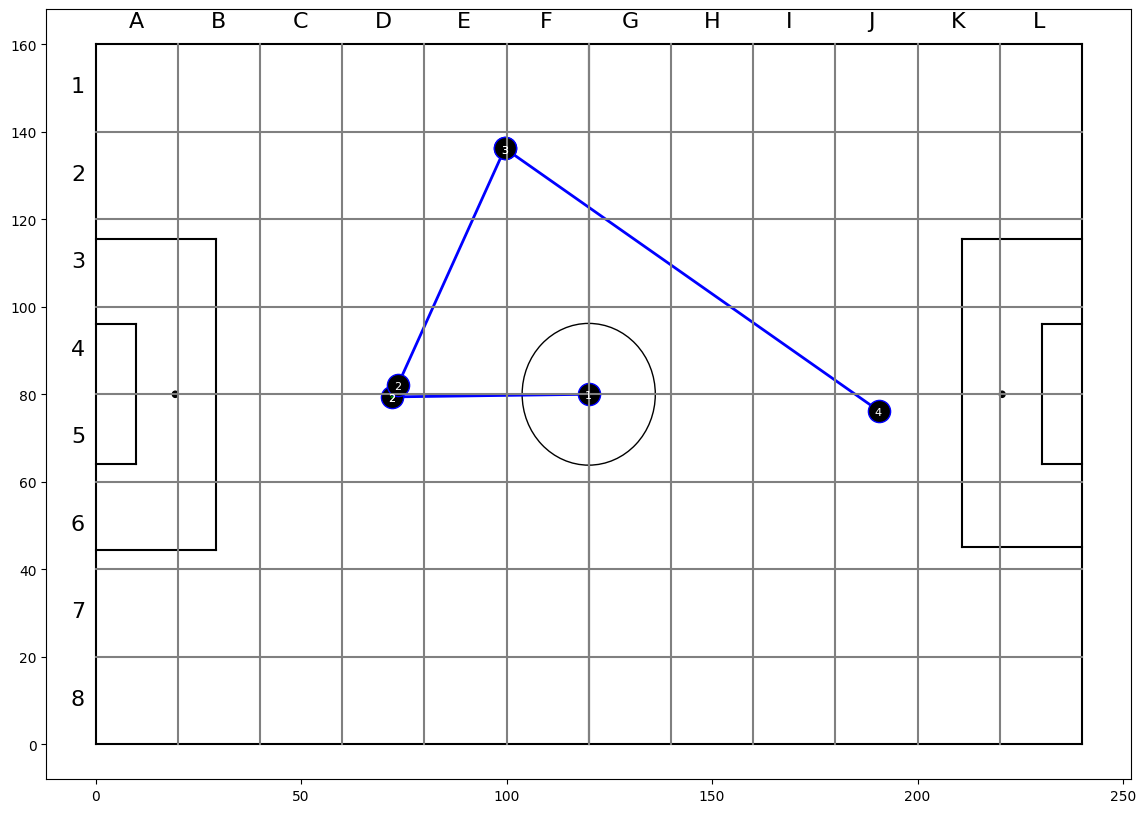

Sequence: 2
Team: Poland
1: Kamil Glik (Pass) <00:00:09.353>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:00:10.310>
2: Mateusz Andrzej Klich (Pass) <00:00:10.344>
3: Piotr Zieliński (Ball Receipt*) <00:00:11.479>
3: Piotr Zieliński (Carry) <00:00:11.479>
3: Piotr Zieliński (Pass) <00:00:13.421>
4: Robert Lewandowski (Ball Receipt*) <00:00:14.364>
4: Robert Lewandowski (Carry) <00:00:14.364>
4: Robert Lewandowski (Pass) <00:00:15.523>
5: Tymoteusz Puchacz (Ball Receipt*) <00:00:16.740>
5: Tymoteusz Puchacz (Carry) <00:00:16.740>
5: Tymoteusz Puchacz (Pass) <00:00:17.456>
6: Jan Bednarek (Ball Receipt*) <00:00:18.427>
6: Jan Bednarek (Carry) <00:00:18.427>
6: Jan Bednarek (Pass) <00:00:19.747>
7: Bartosz Bereszyński (Ball Receipt*) <00:00:21.153>
7: Bartosz Bereszyński (Carry) <00:00:21.153>
7: Bartosz Bereszyński (Pass) <00:00:25.168>
8: Kamil Glik (Ball Receipt*) <00:00:26.550>
8: Kamil Glik (Carry) <00:00:26.550>
8: Kamil Glik (Pass) <00:00:27.497>
9: Jan Bednarek (Ball Receipt*) <00

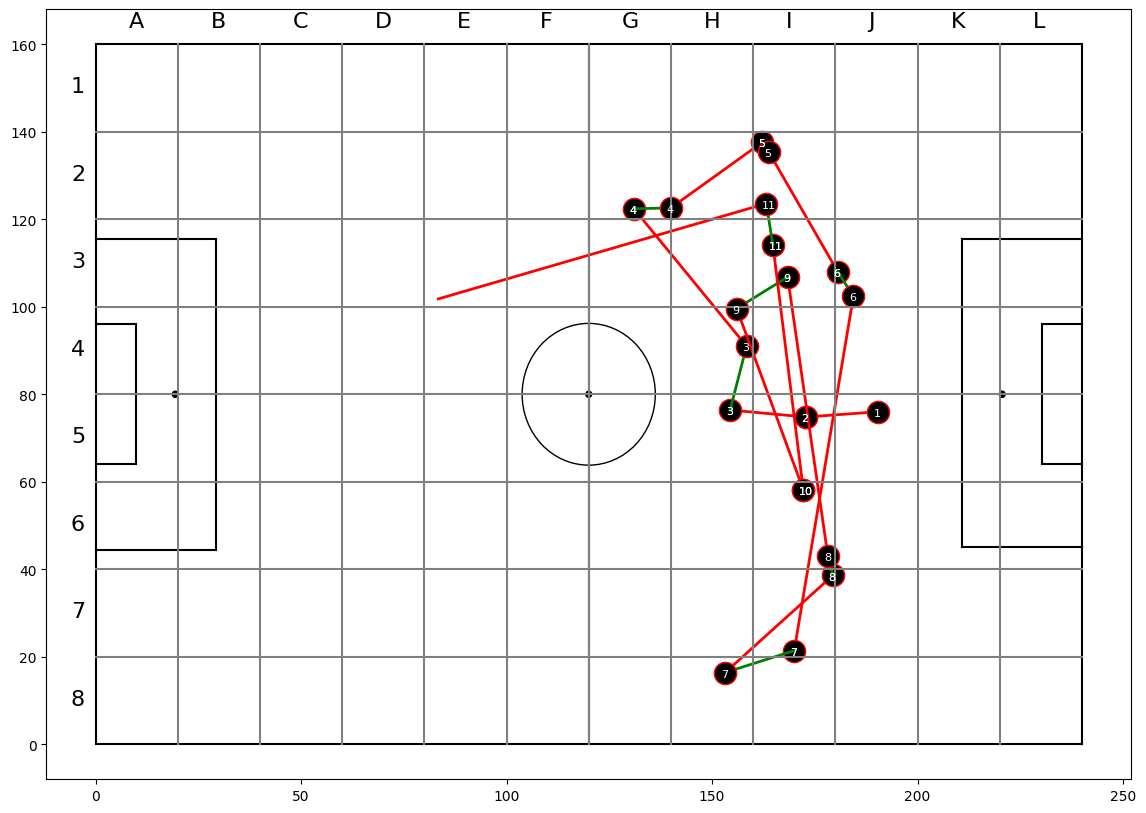

Sequence: 3
Team: Sweden
1: Victor Nilsson Lindelöf (Pass) <00:00:38.375>
2: Kristoffer Olsson (Ball Receipt*) <00:00:39.466>
2: Kristoffer Olsson (Pass) <00:00:39.466>
3: Mikael Lustig (Ball Receipt*) <00:00:40.562>
3: Mikael Lustig (Carry) <00:00:40.562>
3: Mikael Lustig (Pass) <00:00:42.468>


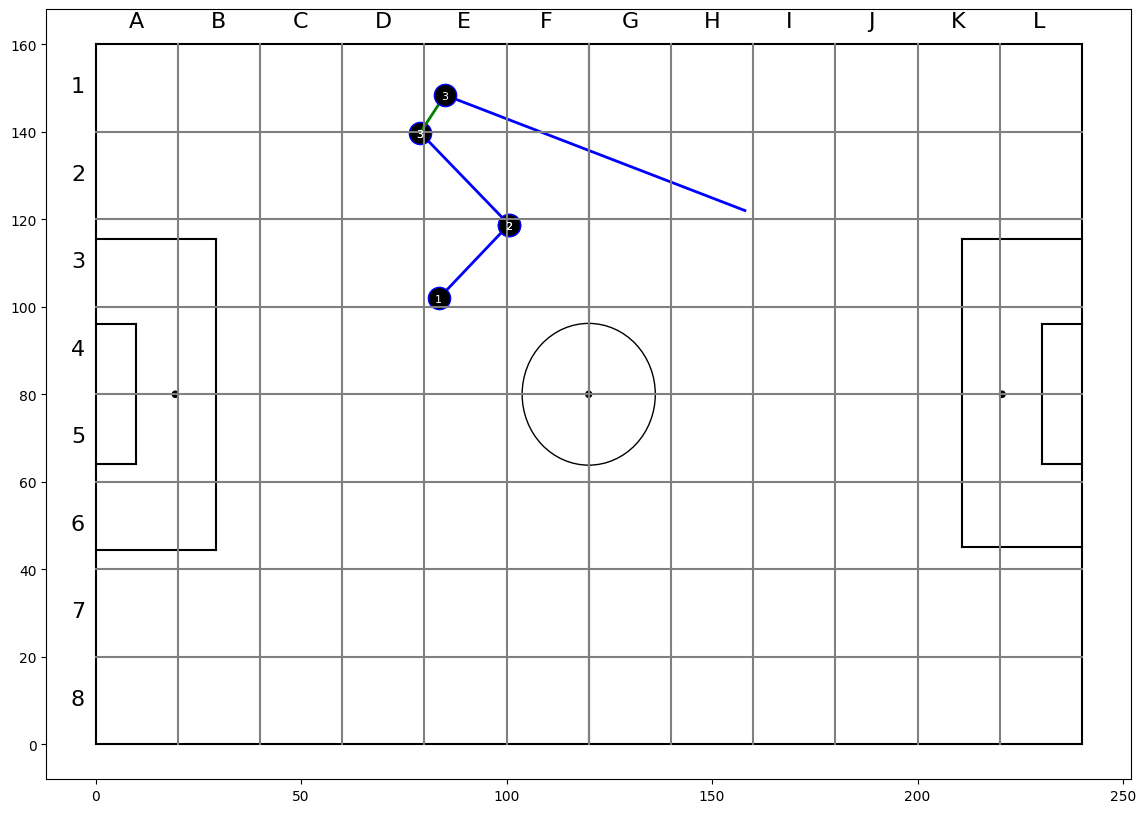

Sequence: 4
Team: Poland
1: Jan Bednarek (Pass) <00:00:44.270>
2: Grzegorz Krychowiak (Ball Receipt*) <00:00:45.101>
2: Grzegorz Krychowiak (Carry) <00:00:45.101>
2: Grzegorz Krychowiak (Pass) <00:00:46.473>
3: Tymoteusz Puchacz (Ball Receipt*) <00:00:47.194>
3: Tymoteusz Puchacz (Carry) <00:00:47.194>
3: Tymoteusz Puchacz (Pass) <00:00:47.847>
4: Mateusz Andrzej Klich (Ball Receipt*) <00:00:48.794>
4: Mateusz Andrzej Klich (Carry) <00:00:48.794>
4: Mateusz Andrzej Klich (Dispossessed) <00:00:50.138>


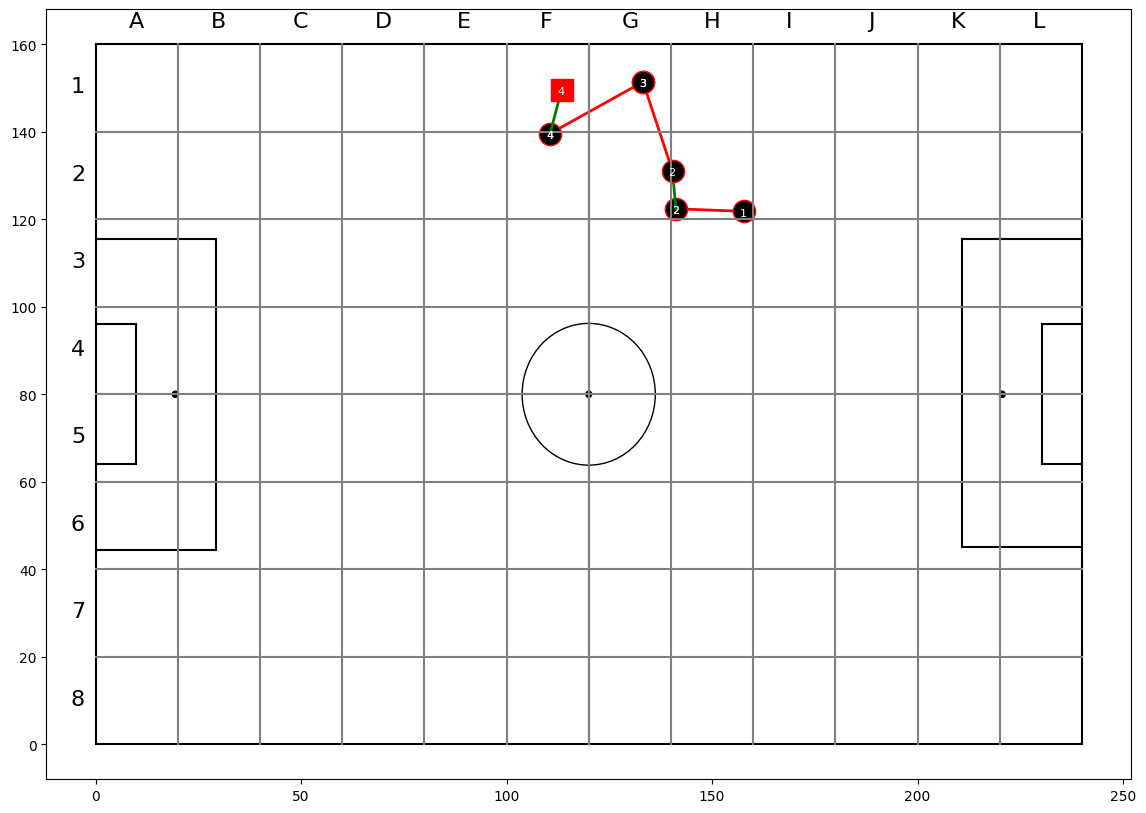

In [6]:
from draw.draw_sequences import draw_events_sequence

start_team = merged_events['possession_team'][0]

for i, s in enumerate(sequences):
    print(f'Sequence: {i+1}')
    draw_events_sequence(s, start_team, 12, 8, scale=2)
    if i == 3:
        break

## Analiza rozkładu wyprowadzanych podań

### Reset dataframe do jednolitej perspektywy

In [7]:
merged_events = get_merged_events(EVENTS_TO_ANALIZE, MATCH_ID)

### Tablica rozkładu podań Polski

In [8]:
from analysis.events_in_area import events_in_area

start_pass_areas_count = events_in_area(merged_events, 'Poland', 'Pass')

start_pass_areas_count[0:5]

d:\Dev\sport-data-science\analysis\events_in_area.py:5: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df = df[events_df['type'] == event]


[('A1', '0.18%'),
 ('A2', '0.18%'),
 ('A3', '0.53%'),
 ('A4', '0.71%'),
 ('A5', '0.71%')]

### Boisko z wypisanym rozkładem wyprowadzanych podań Polski w danej strefie

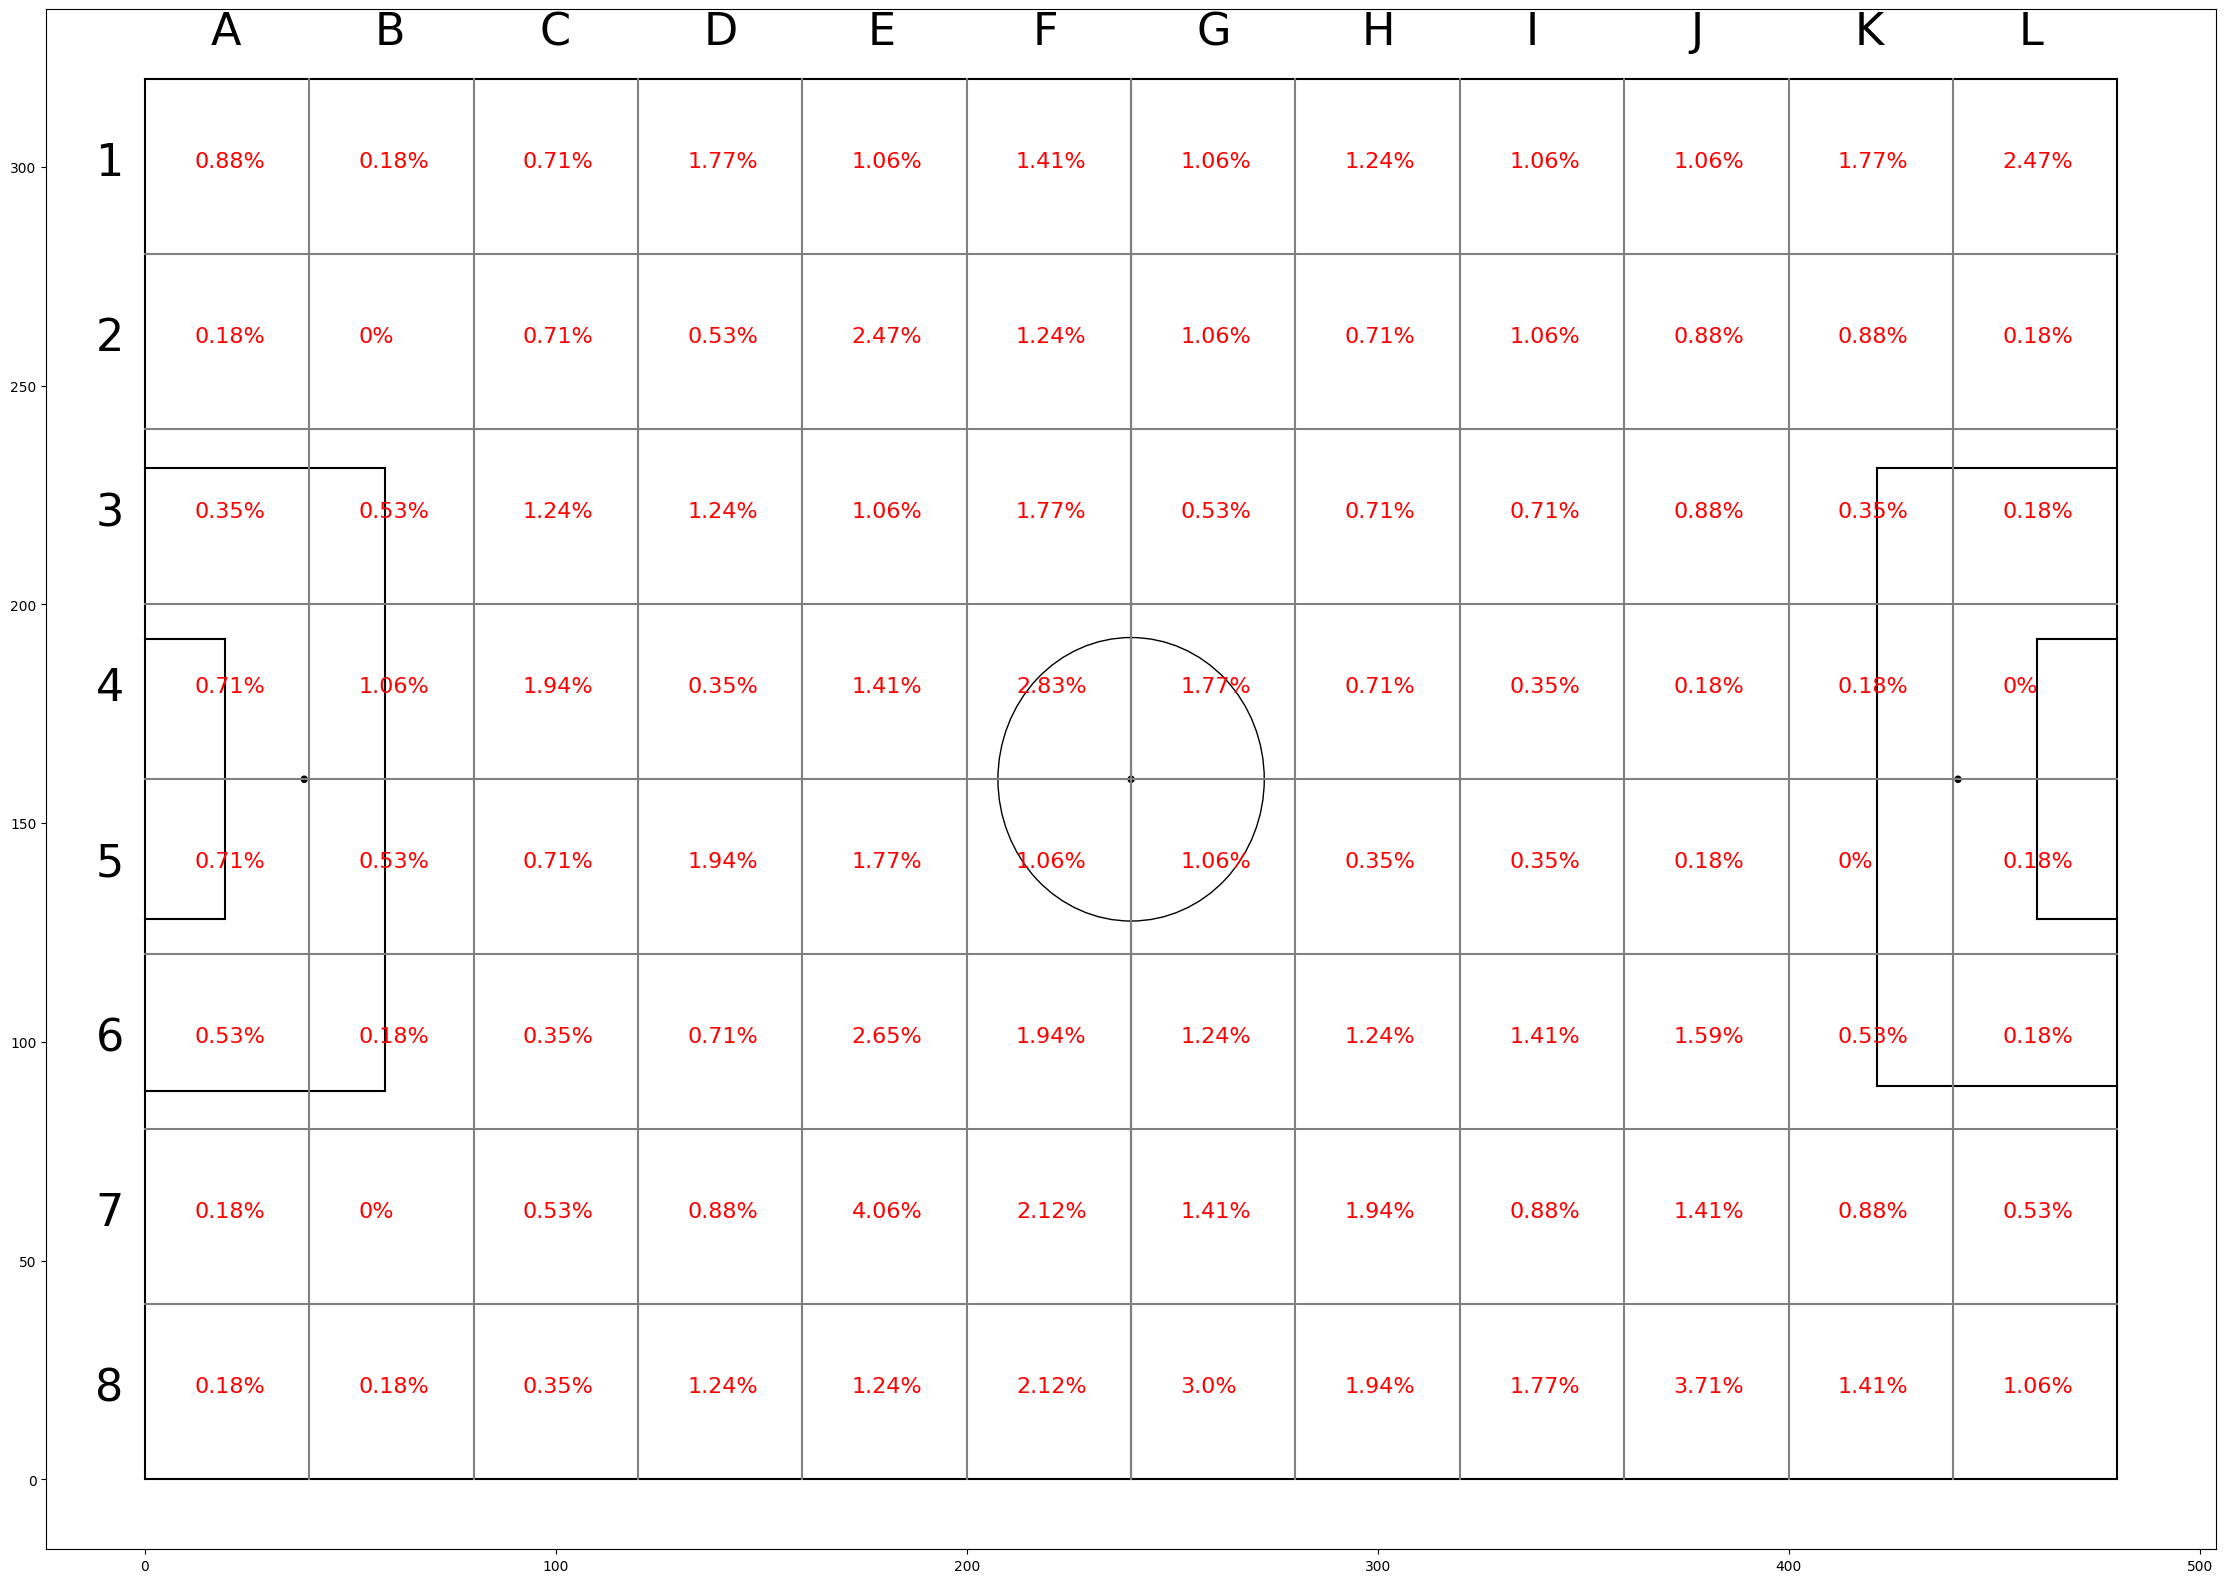

In [9]:
from draw.draw_areas_percents import draw_areas_percents

draw_areas_percents(start_pass_areas_count, 4)

### Wyprowadzane podania przez Polskę jako Mapa Ciepła

In [10]:
from analysis.get_events_locations import get_event_locations

location_xy = get_event_locations(merged_events, 'Pass', 'Poland')
location_xy.head(5)

,x,y
7,24.8,42.0
9,33.6,42.6
12,40.8,34.5
15,50.0,18.7
18,38.1,12.3


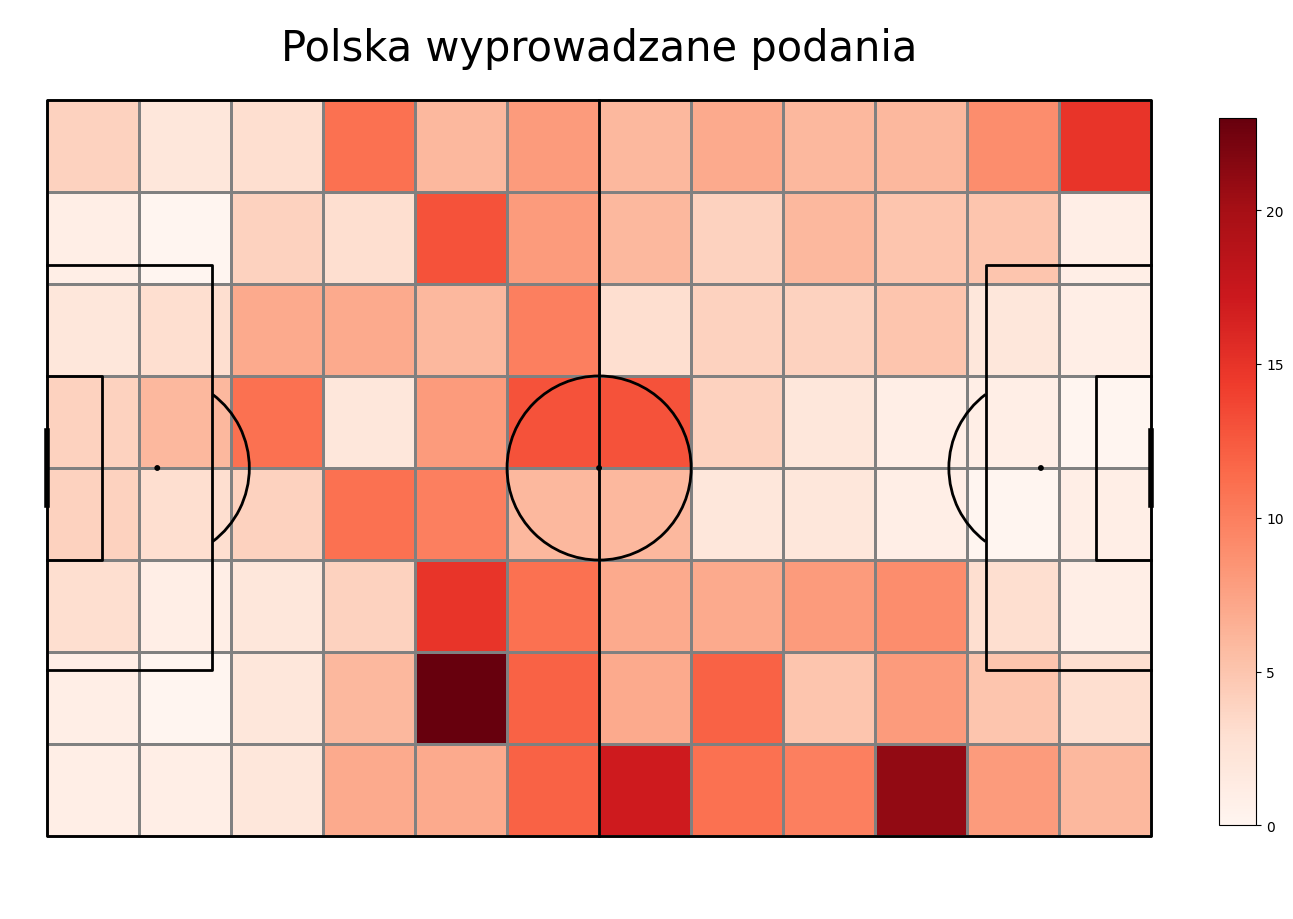

In [11]:
from draw.draw_heatmap import draw_heatmap

draw_heatmap(location_xy=location_xy, title='Polska wyprowadzane podania', x_areas=12, y_areas=8)

### Tablica rozkładu podań Szwecji

In [12]:
start_pass_areas_count = events_in_area(merged_events, 'Sweden', 'Pass')

start_pass_areas_count[0:5]

[('A1', '0%'), ('A2', '0%'), ('A3', '0%'), ('A4', '4.09%'), ('A5', '1.86%')]

### Wypisane rozkłady wyprowadzanych podań Szwecji

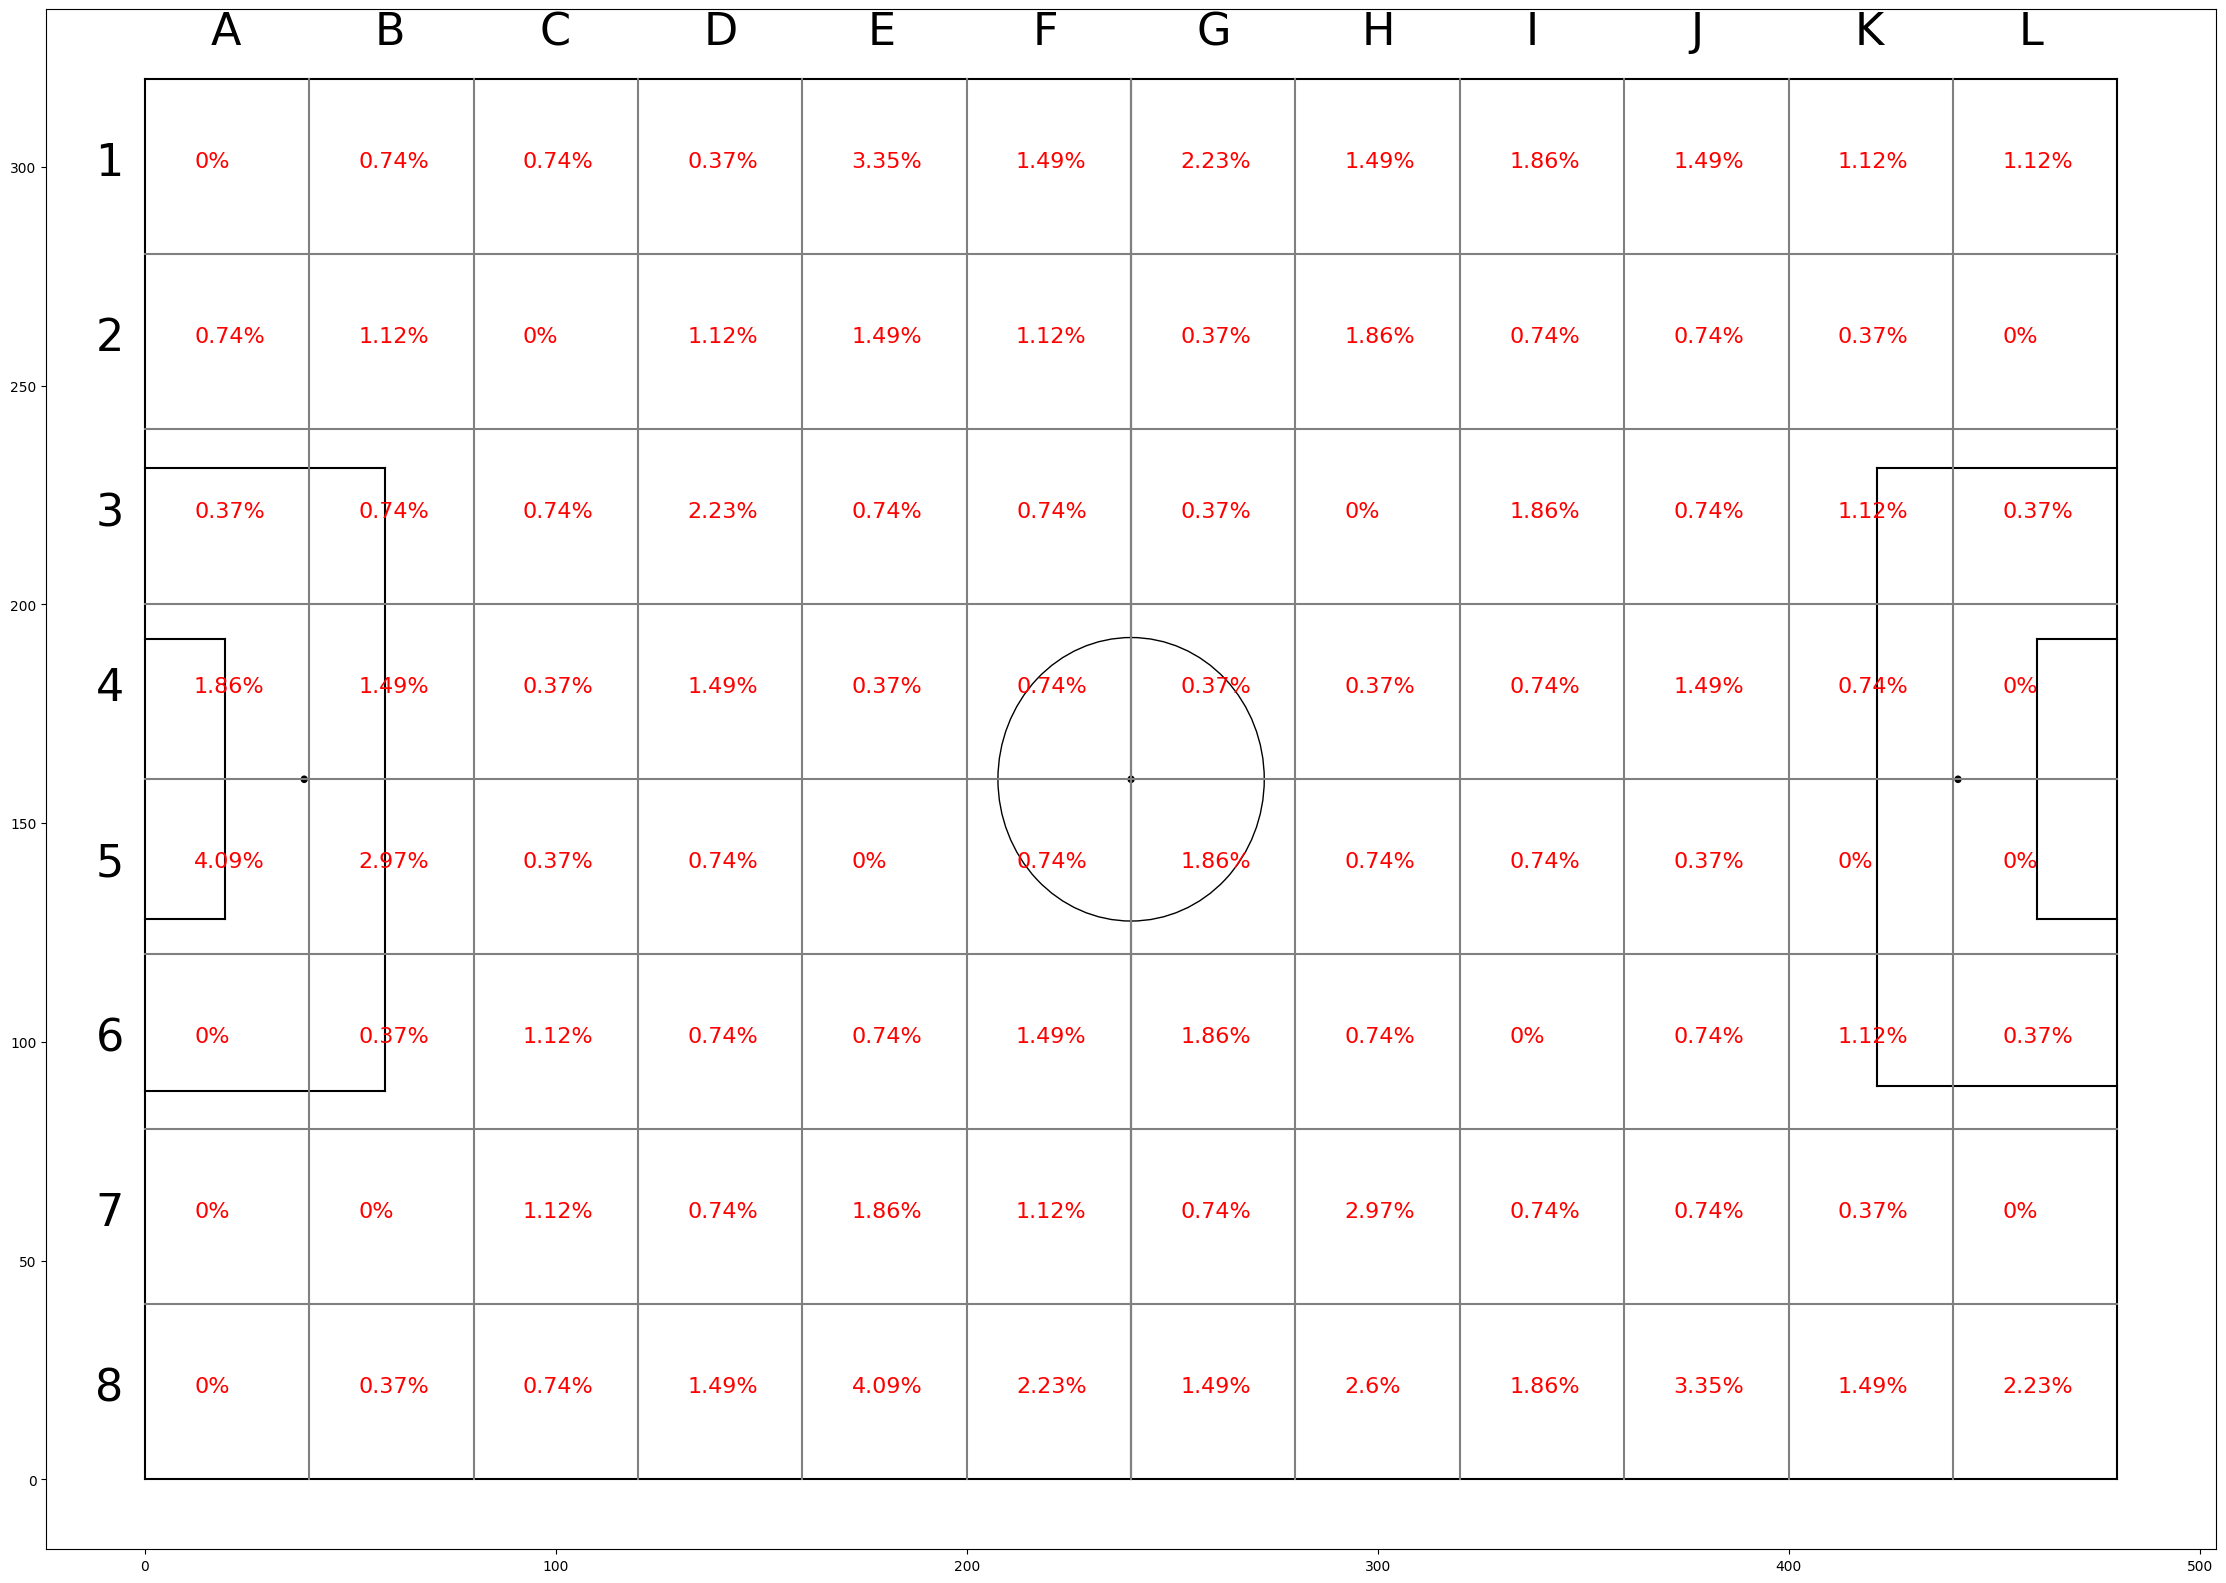

In [13]:
draw_areas_percents(start_pass_areas_count, 4)

### Wyprowadzane podania Szwecji - Mapa Ciepła

In [14]:
location_xy = get_event_locations(merged_events, 'Pass', 'Sweden')
location_xy.head(5)

,x,y
0,60.0,40.0
3,36.8,41.1
5,49.8,68.1
37,41.8,51.0
39,50.3,59.4


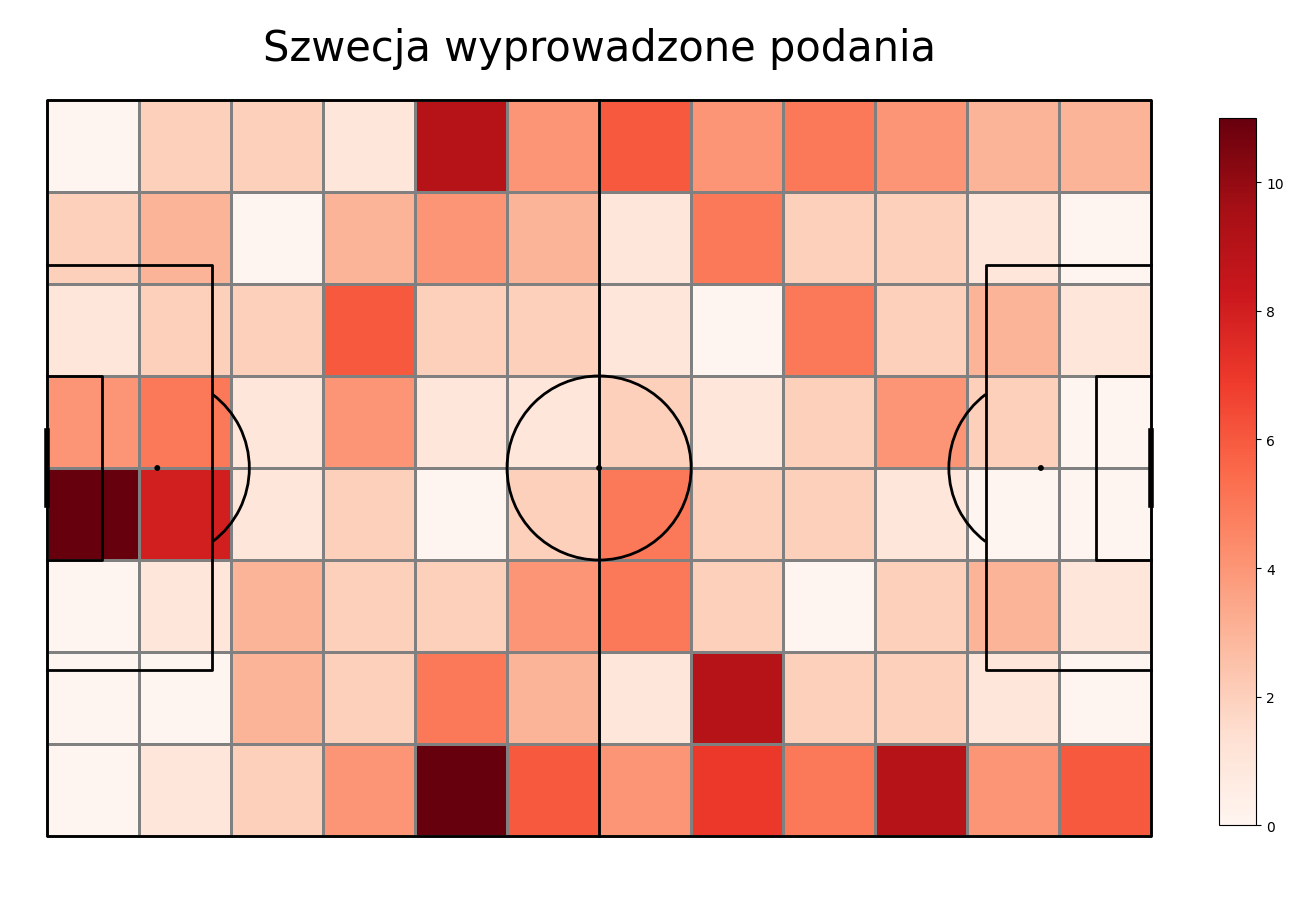

In [15]:
draw_heatmap(location_xy=location_xy, title='Szwecja wyprowadzone podania', x_areas=12, y_areas=8)

## Analiza rozkładu przyjmowanych podań

### Tablica rozkładu przyjęć - Polska

In [16]:
from analysis.events_in_area import events_in_area

end_pass_areas_count = events_in_area(merged_events, 'Poland', 'Ball Receipt*')

end_pass_areas_count[0:5]

[('A1', '0.42%'), ('A2', '0%'), ('A3', '0%'), ('A4', '0.42%'), ('A5', '0.21%')]

### Rysunek rozkładu przyjęć - Polska

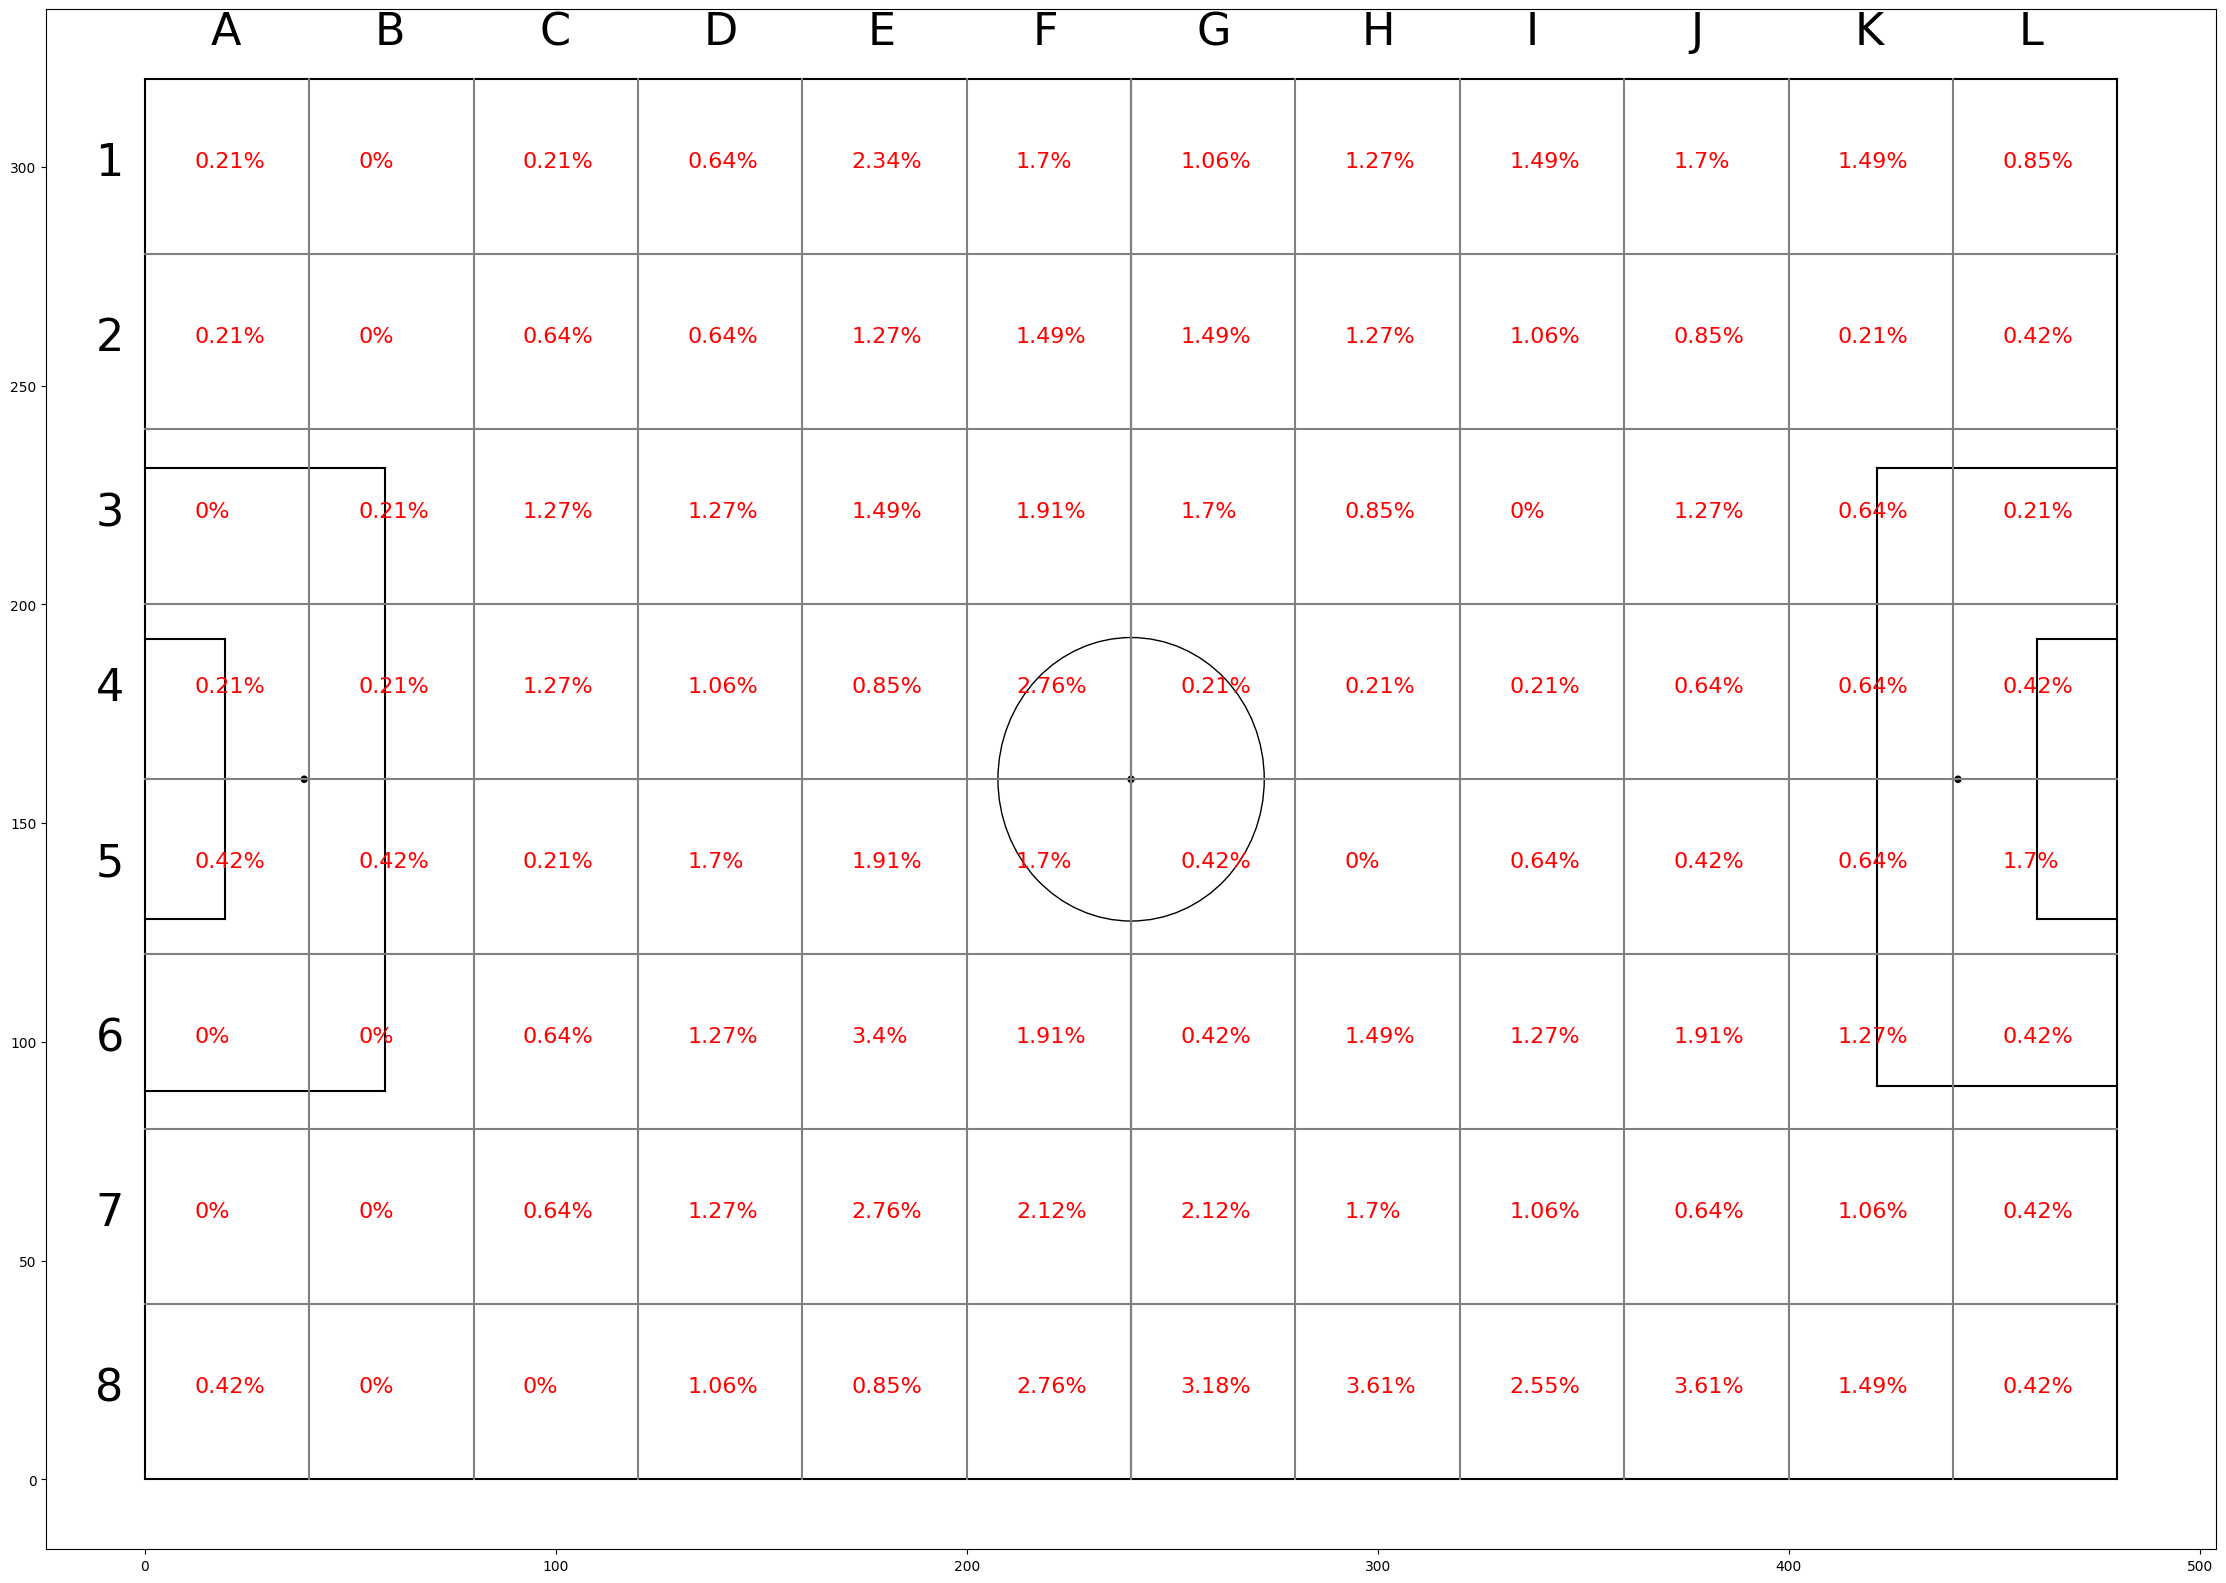

In [17]:
draw_areas_percents(end_pass_areas_count, 4)

### Mapa ciepła przyjęć - Polska

In [18]:
location_xy = get_event_locations(merged_events, 'Ball Receipt*', 'Poland')
location_xy.head(5)

,x,y
8,33.6,42.6
10,42.8,41.8
13,54.5,18.8
16,38.9,11.2
19,29.7,26.0


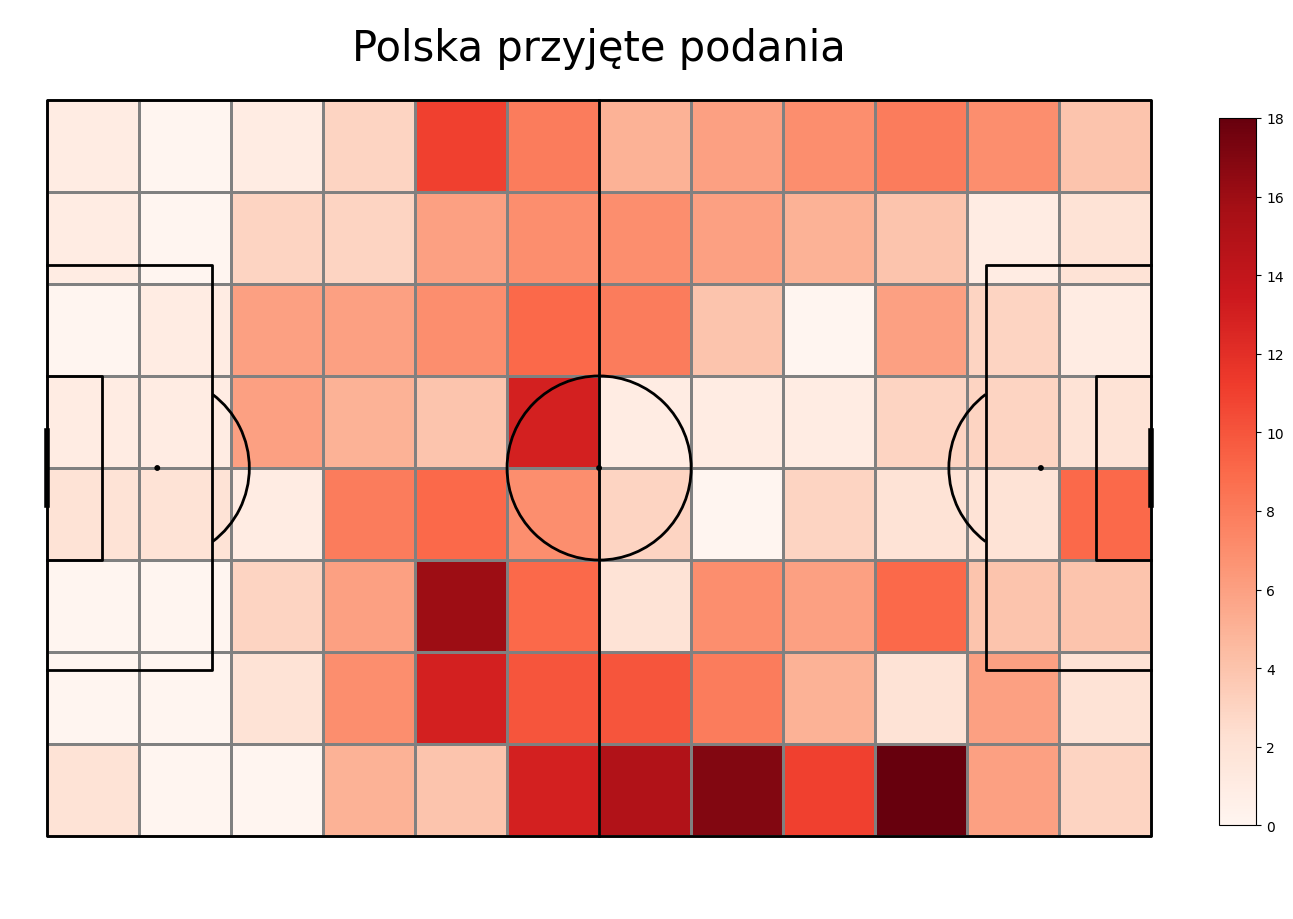

In [19]:
draw_heatmap(location_xy=location_xy, title='Polska przyjęte podania', x_areas=12, y_areas=8)

### Tablica rozkładu przyjęć - Szwecja

In [20]:
from analysis.events_in_area import events_in_area

end_pass_areas_count = events_in_area(merged_events, 'Sweden', 'Ball Receipt*')

end_pass_areas_count[0:5]

[('A1', '0%'), ('A2', '0%'), ('A3', '0%'), ('A4', '0.5%'), ('A5', '0.5%')]

### Rysunek rozkładu przyjęć - Szwecja

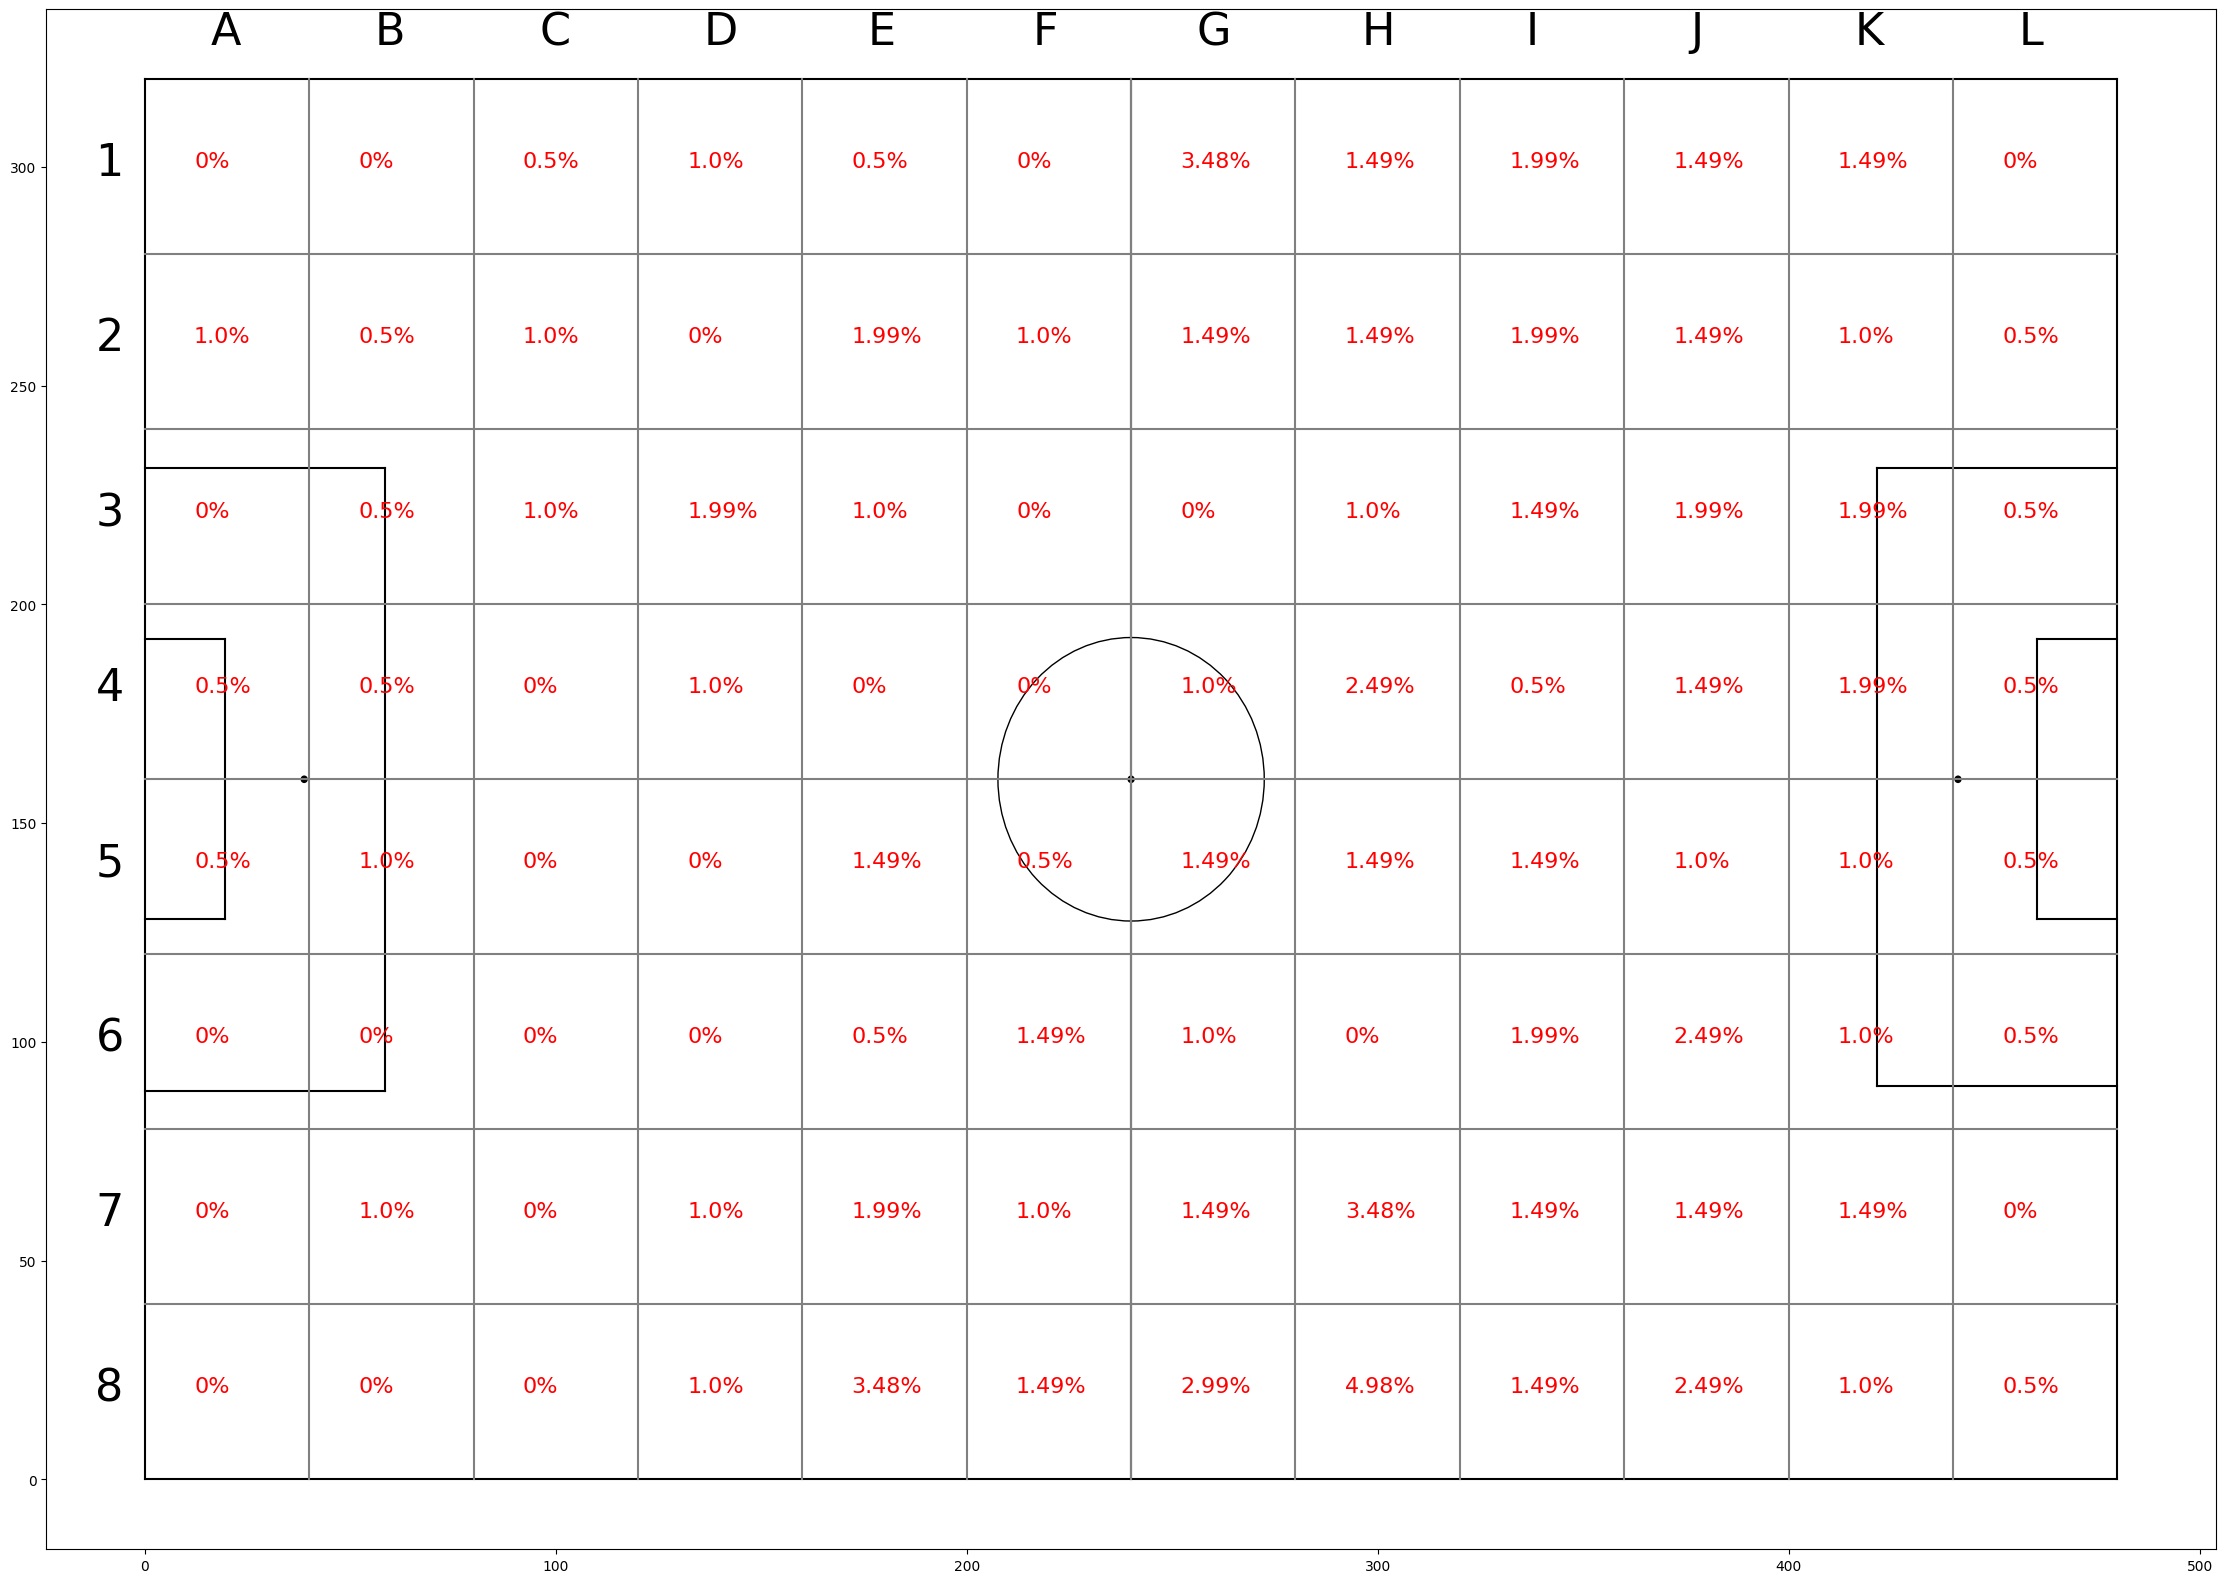

In [21]:
draw_areas_percents(end_pass_areas_count, 4)

### Mapa ciepła przyjęć - Szwecja

In [22]:
location_xy = get_event_locations(merged_events, 'Ball Receipt*', 'Sweden')
location_xy.head(5)

,x,y
1,36.1,39.7
4,49.8,68.1
6,95.3,38.1
38,50.3,59.4
40,39.5,69.9


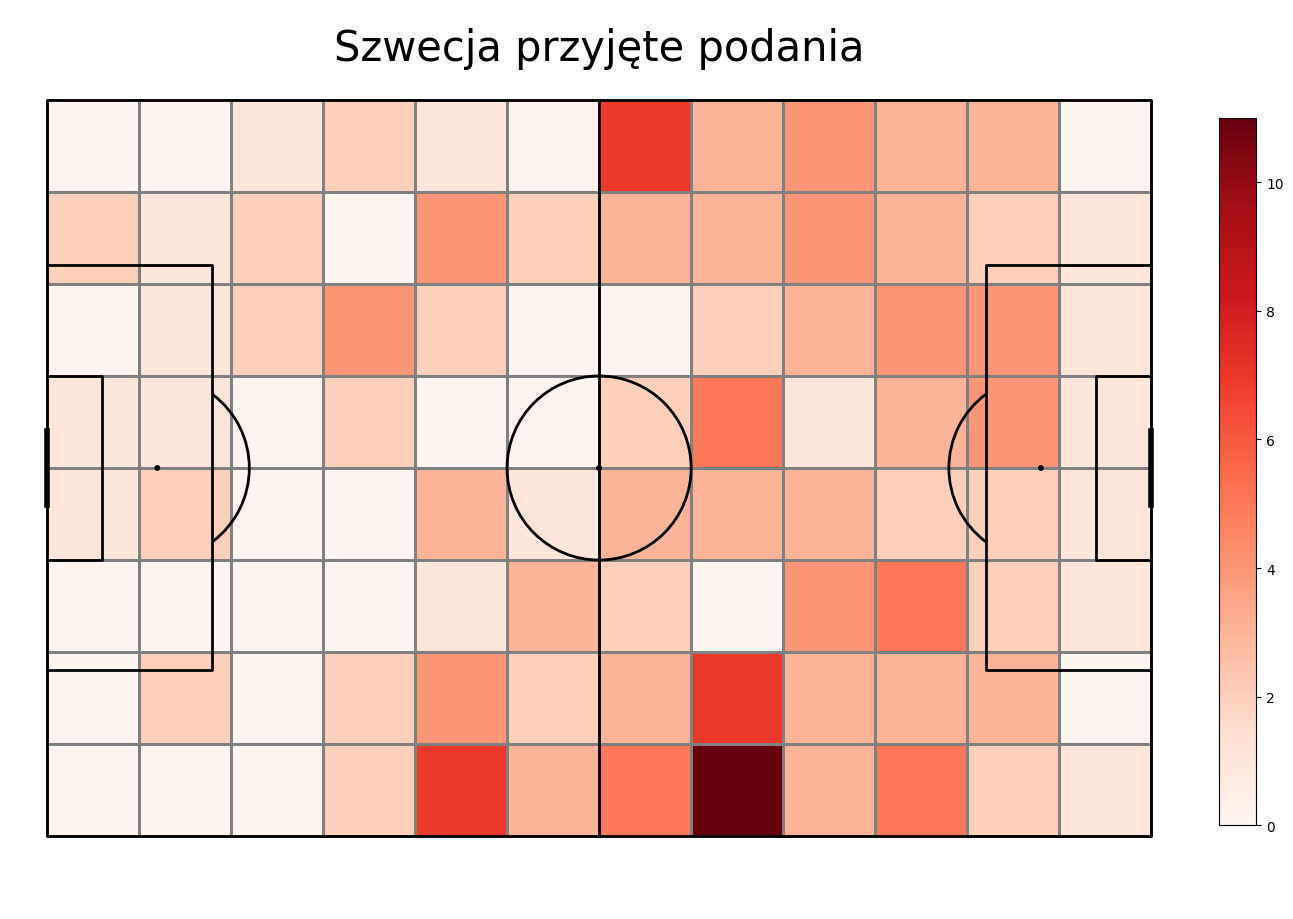

In [23]:
draw_heatmap(location_xy=location_xy, title='Szwecja przyjęte podania', x_areas=12, y_areas=8)